# Sunglint contribution to the TOA signal

In RadCalNet-OC, the TOA signal of the atmosphere and of the sea surface is split into two parts:

- the **diffuse light**, given by the look-up tables: the atmospheric reflectance $R_{atm}$ contains the
  light scattered by the molecules and aerosols and the skylight reflected by the rough sea surface,
  **without the sunglint**;
- the **sunglint**, defined as the **direct sunlight** specularly reflected by the wave facets, which is
  not in the look-up tables and is added to them.

The sunglint is treated as direct light: it is only attenuated by the Beer-Lambert law along the solar and
viewing paths, without any contribution of the diffuse light. This tutorial

1. computes the sunglint reflectance at the surface with the Cox and Munk (1954) statistics of the wave
   slopes ({py:class}`~radcalnet_oc.coxmunk.Sunglint`, see the Sunglint section of {doc}`../../methods`);
2. compares it with the diffuse light of the look-up tables;
3. propagates it to the top of the atmosphere (TOA) and compares it with the RadCalNet-OC simulation of
   the clear-water template, to show for which viewing geometries it cannot be neglected.

The sunglint reflectance $R_g = I_g$ (Eq. {eq}`glint`) is computed for the direct solar beam; at the
TOA, it is attenuated by the direct transmittances along the solar and viewing paths (Beer-Lambert law,
Eq. {eq}`tdir`) and by the gaseous absorption,

$$
R_g^{toa}(\lambda) = T_g^{\downarrow}(\lambda)\, T_g^{\uparrow}(\lambda)\;
\exp\left[ -\left(\tau_r(\lambda)\,\frac{P}{P_0} + \tau_a(\lambda)\right)
\left(\frac{1}{\mu_0} + \frac{1}{\mu_v}\right) \right] R_g,
$$

with $\tau_r$ the Rayleigh optical thickness at $P_0 = 1013.25$ hPa, $P$ the surface pressure and
$\tau_a$ the aerosol optical thickness. The refractive index of water is constant (1.334): $R_g$ does not
depend on the wavelength and the spectral shape of $R_g^{toa}$ is that of the transmittances.

```{note}
**Azimuth conventions.** In the look-up tables and in {py:class}`~radcalnet_oc.process.Process`, the
relative azimuth angle $\phi$ is 0° when the viewing direction points towards the Sun (sunglint geometry);
in {py:class}`~radcalnet_oc.coxmunk.Sunglint`, the specular reflection is at 180°. All the figures of this
tutorial use the convention of the look-up tables, and {py:class}`~radcalnet_oc.coxmunk.Sunglint` is
called with $180° - \phi$.
```

In [1]:
import logging
from importlib.resources import files

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)
print(f'radcalnet_oc: {radoc.__version__}')

radcalnet_oc: 0.0.3


## Sunglint at the surface

{py:class}`~radcalnet_oc.coxmunk.Sunglint` computes the Stokes vector of the sunglint reflectance for one
geometry; the helper below loops over a grid of viewing zenith and relative azimuth angles. The slope
statistics of Bréon and Henriot (2006) are used (`stats='bh2006'`), with the downwind direction along
the solar azimuth (`wazi=0`) and the shadowing of the facets by the waves.

In [2]:
def sunglint_reflectance(sza, vza, azi, ws, wazi=0, stats='bh2006'):
    """Sunglint reflectance at the surface on a (vza, azi) grid, azi in the convention of the LUT."""
    Rg = np.empty((len(vza), len(azi)))
    for i, v in enumerate(vza):
        for j, a in enumerate(azi):
            Rg[i, j] = radoc.Sunglint(sza, v, 180. - a).sunglint(ws, wazi, stats=stats)[0]
    # the Gram-Charlier expansion of the slope distribution can be slightly negative far from the
    # specular direction for strong winds: the reflectance is set to 0 there
    Rg = np.clip(Rg, 0, None)
    return xr.DataArray(Rg, coords={'vza': vza, 'azi': azi}, dims=('vza', 'azi'), name='Rg')


def polar_map(ax, data, norm, cmap=plt.cm.Spectral_r):
    """Half polar plot: relative azimuth as polar angle (0 = towards the Sun), viewing zenith as radius."""
    cmap = cmap.copy()
    cmap.set_bad(cmap(0))  # null values (log scale)
    im = ax.pcolormesh(np.radians(data.azi), data.vza, data.transpose('vza', 'azi'), norm=norm, cmap=cmap,
                       shading='auto')
    ax.set_thetamin(0)
    ax.set_thetamax(180)
    ax.set_rlabel_position(90)
    ax.grid(color='grey', lw=0.5, alpha=0.6)
    return im

Sunglint reflectance for a solar zenith angle of 30° and three wind speeds. The glint is centred on the
specular direction ($\theta_v = \theta_0$, $\phi = 0$): the rougher the sea, the wider and the weaker the
glint spot.

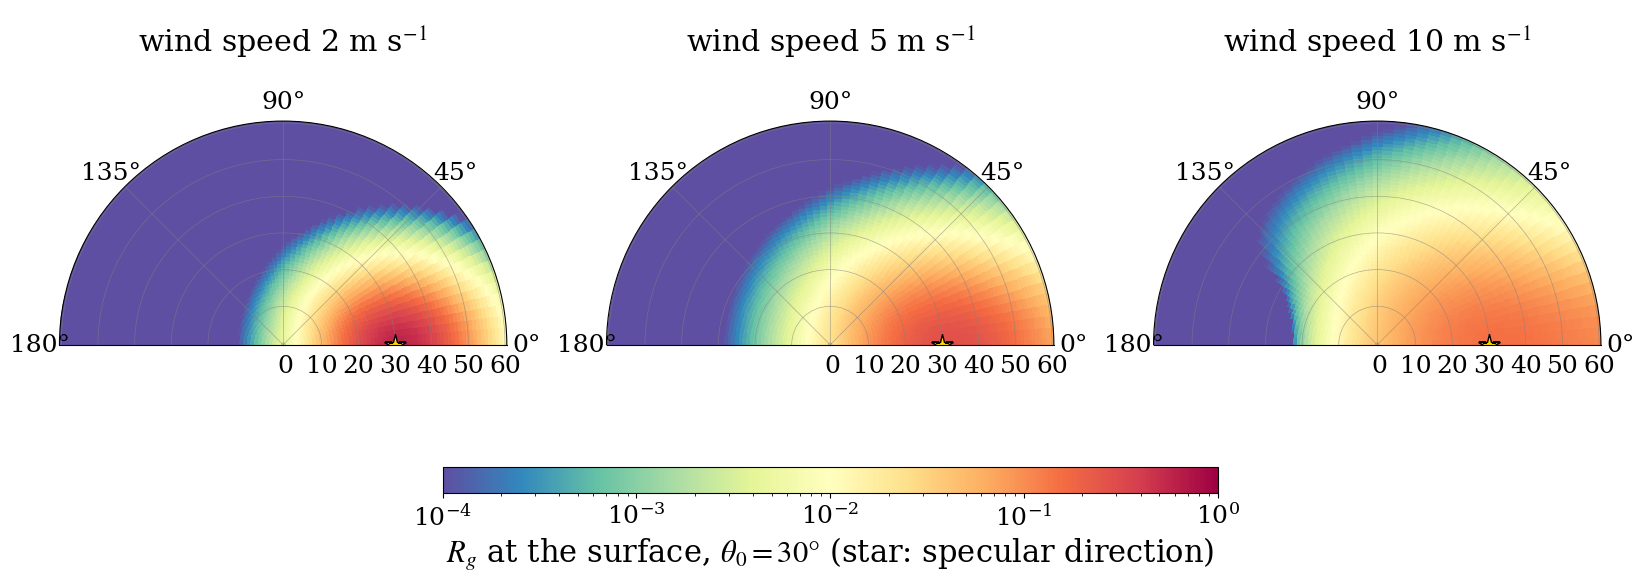

In [3]:
sza = 30.
vza_grid = np.linspace(0, 60, 61)
azi_grid = np.linspace(0, 180, 61)
winds = [2, 5, 10]

norm = mpl.colors.LogNorm(vmin=1e-4, vmax=1)
fig, axs = plt.subplots(1, 3, figsize=(20, 7), subplot_kw={'projection': 'polar'})
for ax, ws in zip(axs, winds):
    Rg = sunglint_reflectance(sza, vza_grid, azi_grid, ws)
    im = polar_map(ax, Rg, norm)
    ax.plot(0, sza, '*', color='gold', ms=16, mec='k')
    ax.set_title(f'wind speed {ws} m s$^{{-1}}$', pad=-30)
cb = fig.colorbar(im, ax=axs, shrink=0.5, aspect=30, location='bottom', pad=0.02)
cb.set_label(r'$R_g$ at the surface, $\theta_0 = 30°$ (star: specular direction)')
plt.show()

Along the principal plane, for the three slope statistics of the module (isotropic and directional
Cox and Munk statistics, Bréon and Henriot): the viewing zenith angle is counted positive towards the
Sun ($\phi = 0$) and negative on the opposite side ($\phi = 180°$). Far from the specular direction and
for strong winds, the Gram-Charlier expansion of the directional statistics can become negative; the
reflectance is then set to 0.

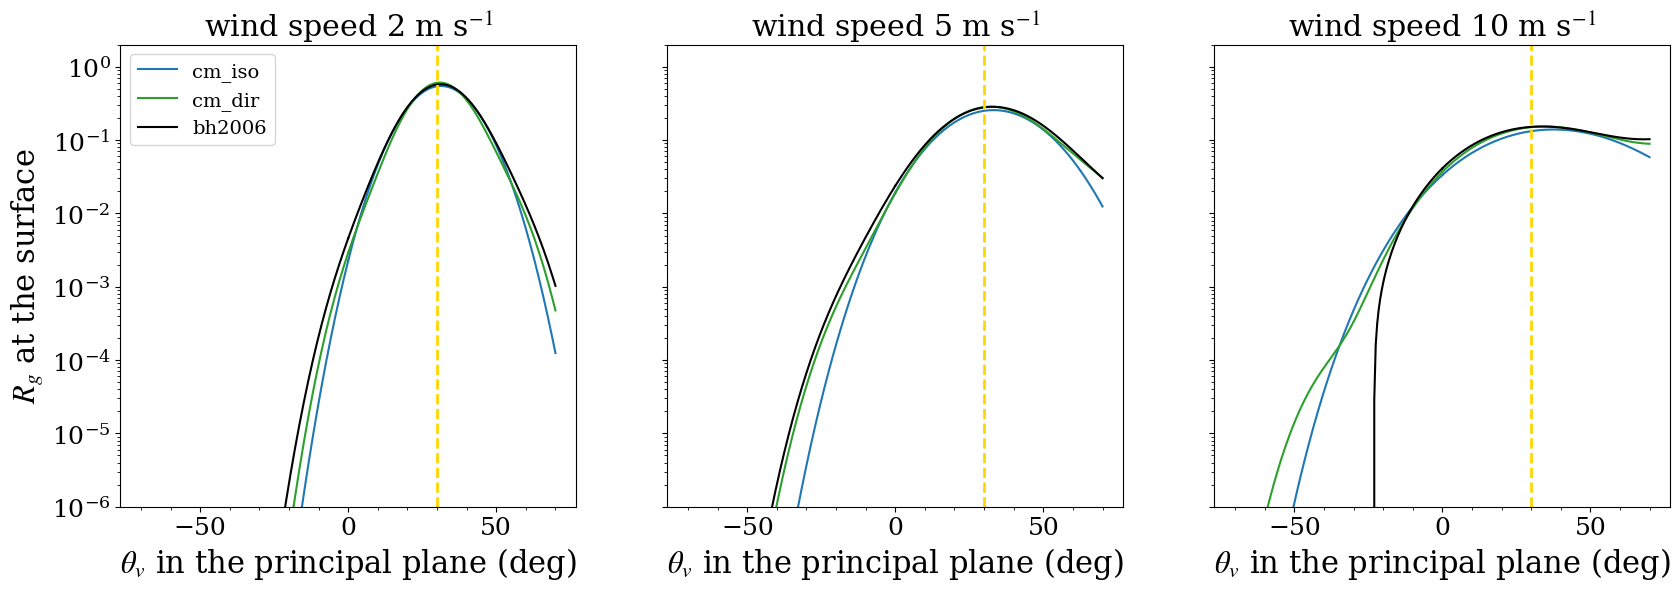

In [4]:
vza_pp = np.linspace(0, 70, 141)
fig, axs = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, ws in zip(axs, winds):
    for stats, color in zip(['cm_iso', 'cm_dir', 'bh2006'], ['tab:blue', 'tab:green', 'k']):
        forward = sunglint_reflectance(sza, vza_pp, [0.], ws, stats=stats).squeeze()
        backward = sunglint_reflectance(sza, vza_pp, [180.], ws, stats=stats).squeeze()
        ax.semilogy(vza_pp, forward, color=color, label=stats)
        ax.semilogy(-vza_pp, backward, color=color)
    ax.axvline(sza, color='gold', lw=2, ls='--')
    ax.set_title(f'wind speed {ws} m s$^{{-1}}$')
    ax.set_xlabel(r'$\theta_v$ in the principal plane (deg)')
    ax.set_ylim(1e-6, 2)
    ax.minorticks_on()
axs[0].set_ylabel(r'$R_g$ at the surface')
axs[0].legend(fontsize=14)
plt.show()

## Diffuse light of the look-up tables and direct sunglint

The atmospheric reflectance $R_{atm} = I/\mu_0$ of the look-up tables (Eq. {eq}`ratm`), i.e. the diffuse
light, is compared along the principal plane with the direct sunglint attenuated by the Beer-Lambert law, for an aerosol
optical thickness of 0.1 at 550 nm (default aerosol models), at the wavelengths of the tables where the
atmospheric signal is low (800, 1600 and 2200 nm). The look-up tables are prepared at their own viewing
zenith angles and for two of their wind speeds (2 and 8 m s$^{-1}$); the gaseous absorption is left out.

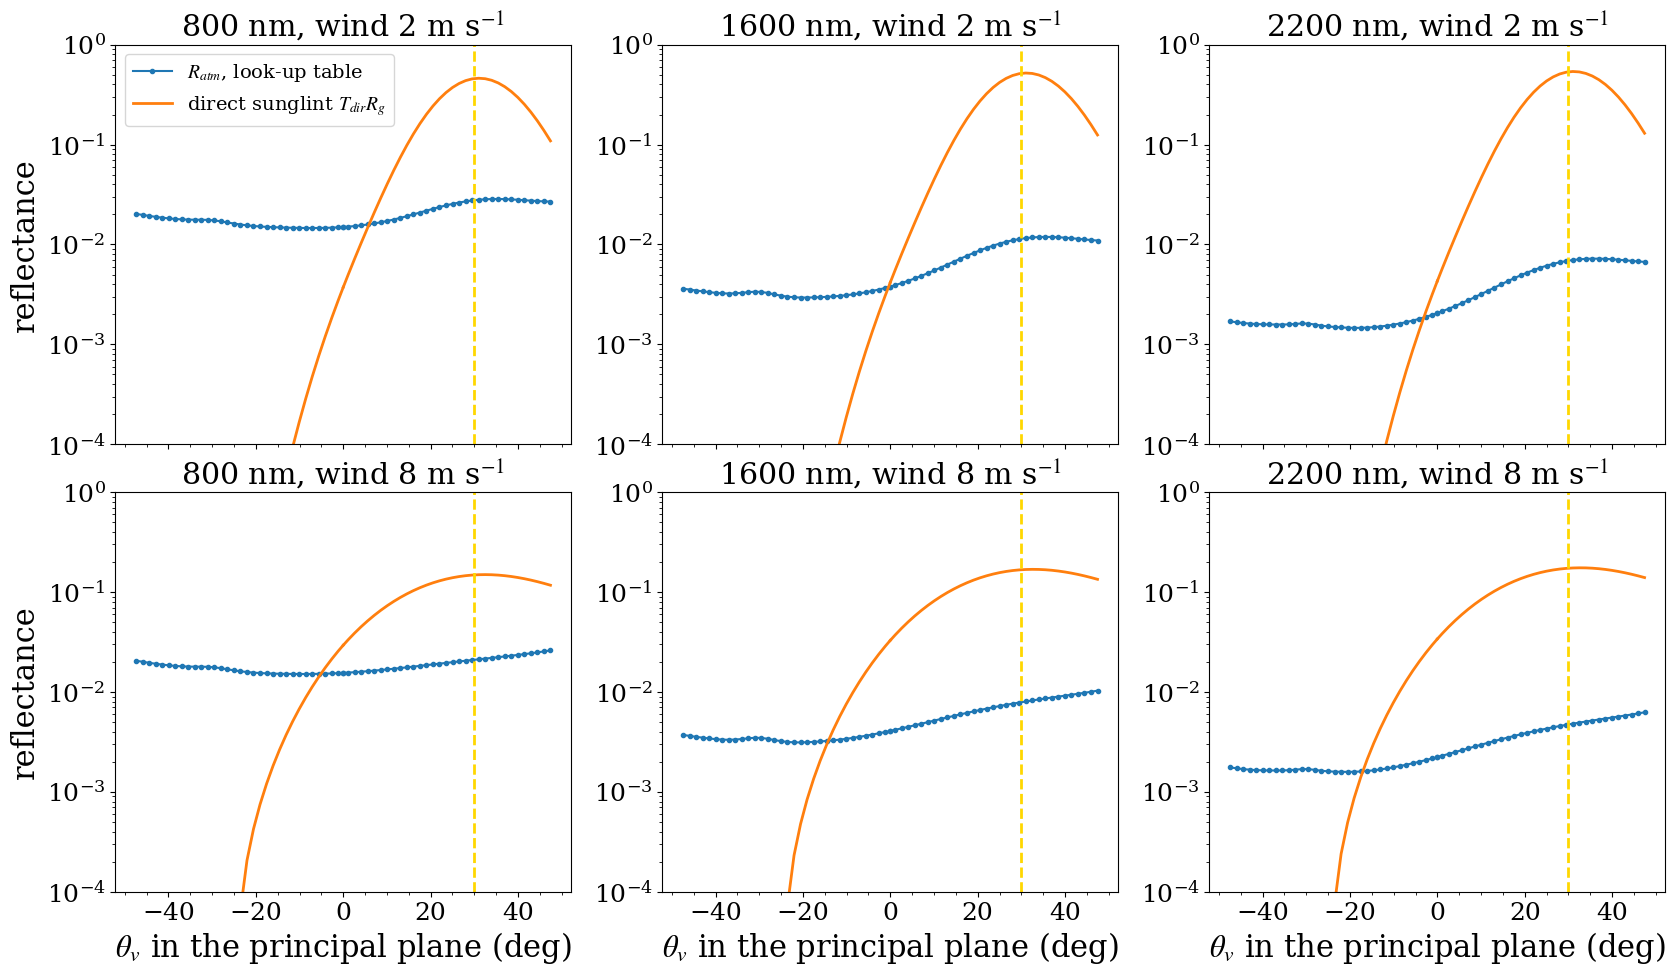

In [5]:
lut = radoc.LUT()
vza_lut = lut.aero_lut.vza.values[lut.aero_lut.vza.values <= 48]
aot550 = 0.1
wls = [800., 1600., 2200.]

fig, axs = plt.subplots(2, 3, figsize=(20, 11), sharex=True)
fig.subplots_adjust(hspace=0.12)
for irow, ws in enumerate([2, 8]):
    lut.lut_preparation(wind=ws, sza=[sza], vza=vza_lut, azi=[0., 180.], aot_refs=[aot550])
    Ratm = lut.Rdiff_lut.squeeze()

    # direct transmittance along the Sun-surface-sensor path
    tau = lut.rot.interp(wl=Ratm.wl) + lut.aot_lut.sel(aot_ref=aot550, method='nearest').interp(wl=Ratm.wl)
    air_mass = 1 / np.cos(np.radians(sza)) + 1 / np.cos(np.radians(Ratm.vza))
    Tdir = np.exp(-tau * air_mass)
    Rg = sunglint_reflectance(sza, vza_lut, [0., 180.], ws)
    Rg_toa = Tdir * Rg

    for ax, wl in zip(axs[irow], wls):
        for azi, sign in [(0., 1), (180., -1)]:
            ax.semilogy(sign * Ratm.vza, Ratm.sel(wl=wl, azi=azi), 'o-', color='tab:blue', ms=3,
                        label=r'$R_{atm}$, look-up table' if azi == 0 else None)
            ax.semilogy(sign * Rg_toa.vza, Rg_toa.sel(wl=wl, azi=azi), '-', color='tab:orange', lw=2,
                        label=r'direct sunglint $T_{dir} R_g$' if azi == 0 else None)
        ax.axvline(sza, color='gold', lw=2, ls='--')
        ax.set_title(f'{wl:.0f} nm, wind {ws} m s$^{{-1}}$')
        ax.set_ylim(1e-4, 1)
        ax.minorticks_on()
for ax in axs[:, 0]:
    ax.set_ylabel('reflectance')
for ax in axs[1]:
    ax.set_xlabel(r'$\theta_v$ in the principal plane (deg)')
axs[0, 0].legend(fontsize=14, loc='upper left')
plt.show()

Towards the Sun, the diffuse light of the look-up tables increases with the skylight reflected by the
surface, but it stays one to two orders of magnitude below the direct sunglint around the specular
direction: as expected, the look-up tables, and hence $R_{atm}$ and the TOA reflectance of
{py:class}`~radcalnet_oc.process.Process`, do not contain the sunglint. The direct sunglint computed
here must be added to them, or the geometries where it is significant must be avoided, when the
simulations are compared with satellite observations.

## Sunglint at the top of the atmosphere

The clear-water template of the package is simulated for two of its measurements, a grid of viewing
zenith angles (0 to 45°) and relative azimuth angles (0 to 180°). The look-up tables are used for the
default wind speed of {py:meth}`LUT.lut_preparation <radcalnet_oc.lut.LUT.lut_preparation>`
(2 m s$^{-1}$).

In [6]:
template = xr.open_dataset(files('radcalnet_oc.data.template') / 'template_clear_water.nc')
input_db = template.isel(time=[10, 11])

vza = xr.DataArray(np.arange(0., 46., 2.5), dims='vza')
vza = vza.assign_coords(vza=vza)
azi = xr.DataArray(np.arange(0., 181., 7.5), dims='azi')
azi = azi.assign_coords(azi=azi)

process = radoc.Process(input_db=input_db, vza=vza, azi=azi)
process.execute()
Rtoa = process.radcalnet_db.Rtoa
print(f'sza = {input_db.sza.values.round(1)} deg, aot(550) = {input_db.aot550.values.round(3)}')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/radcalnet_oc/radcalnet_oc/lut.py:524: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  solar_irr = xr.open_dataset(thuillier_file).squeeze().data.drop('time') * 1e3


sza = [28.1 31.2] deg, aot(550) = [0.161 0.146]


The sunglint being direct light, it is attenuated by the Beer-Lambert law only (no diffuse
transmittance): the direct transmittance is computed with the Rayleigh optical thickness at the surface pressure and the
aerosol optical thickness of the aerosol mixture of the simulation, both interpolated at the wavelengths
of the simulation; the gaseous transmittances are those of the simulation. The sunglint is computed for
three wind speeds.

In [7]:
full_wl = process.full_wl
mu0 = np.cos(np.radians(input_db.sza))
muv = np.cos(np.radians(vza))

tau_r = process.lut.rot.interp(wl=full_wl, kwargs={'fill_value': 'extrapolate'}) * input_db.pressure / 1013.25
tau_a = process.lut.aot_lut.interp(aot_ref=input_db.aot550).interp(wl=full_wl, method='quadratic')
Tdir = np.exp(-(tau_r + tau_a) * (1 / mu0 + 1 / muv))
Tg = process.Tg_d.sel(wl=full_wl) * process.Tg_u.sel(wl=full_wl)
# spectral range of the figures, to limit the memory
Tdir, Tg = Tdir.sel(wl=slice(400, 1100)), Tg.sel(wl=slice(400, 1100))

Rg = xr.concat([xr.concat([sunglint_reflectance(float(s), vza.values, azi.values, ws) for s in input_db.sza.values],
                          dim=input_db.time)
                for ws in winds], dim=xr.DataArray(winds, dims='wind', name='wind'))
Rg_toa = (Tg * Tdir * Rg).transpose('wind', 'time', 'wl', 'vza', 'azi').rename('Rg_toa')
print(dict(Rg_toa.sizes))

{'wind': 3, 'time': 2, 'wl': 15909, 'vza': 19, 'azi': 25}


### Spectra

TOA reflectance of the simulation (water + atmosphere, black) and sunglint reflectance at the TOA for the
three wind speeds, for a viewing zenith angle of 30° at three relative azimuth angles. The spectra are
convolved with Gaussian spectral responses of 3 nm FWHM ({py:meth}`Spectral.convolve2
<radcalnet_oc.lut.Spectral.convolve2>`). Close to the
specular direction, the sunglint exceeds the whole signal of the simulation; at 90° from the Sun, it
remains significant in the near infrared for a rough sea.

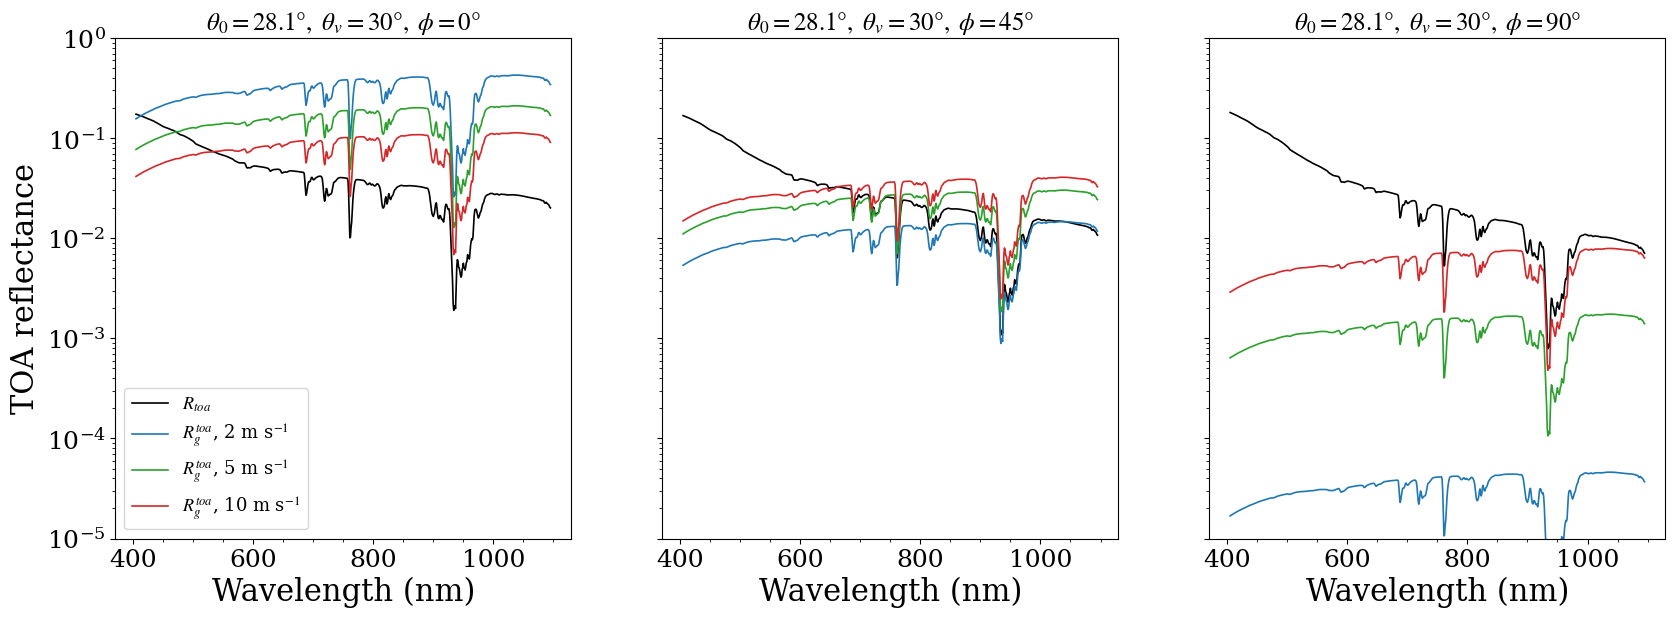

In [8]:
colors = {2: 'tab:blue', 5: 'tab:green', 10: 'tab:red'}
geometries = [(30., 0.), (30., 45.), (30., 90.)]
it = 0

spectral = radoc.Spectral(central_wl=np.arange(405., 1096., 1.), fwhm=3.)
sel = dict(vza=sorted({v for v, a in geometries}), azi=sorted({a for v, a in geometries}))
Rtoa_3nm = spectral.convolve2(Rtoa.isel(time=it).sel(**sel).rename('Rtoa')).Rtoa
Rg_toa_3nm = spectral.convolve2(Rg_toa.isel(time=it).sel(**sel)).Rg_toa

fig, axs = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
for ax, (v, a) in zip(axs, geometries):
    Rtoa_3nm.sel(vza=v, azi=a).plot(ax=ax, color='k', lw=1.2, label=r'$R_{toa}$')
    for ws in winds:
        Rg_toa_3nm.sel(wind=ws, vza=v, azi=a).plot(ax=ax, color=colors[ws], lw=1.2,
                                                   label=f'$R_g^{{toa}}$, {ws} m s$^{{-1}}$')
    ax.set_yscale('log')
    ax.set_ylim(1e-5, 1)
    ax.set_title(r'$\theta_0 = %.1f°,\ \theta_v = %.0f°,\ \phi = %.0f°$' % (input_db.sza[it], v, a), fontsize=18)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('')
    ax.minorticks_on()
axs[0].set_ylabel('TOA reflectance')
axs[0].legend(fontsize=13, loc='lower left')
plt.show()

### Relative contribution

Ratio of the sunglint to the TOA reflectance of the simulation at 560 and 865 nm, over the viewing
geometries. The white contours mark a contribution of 1 % and 10 %.

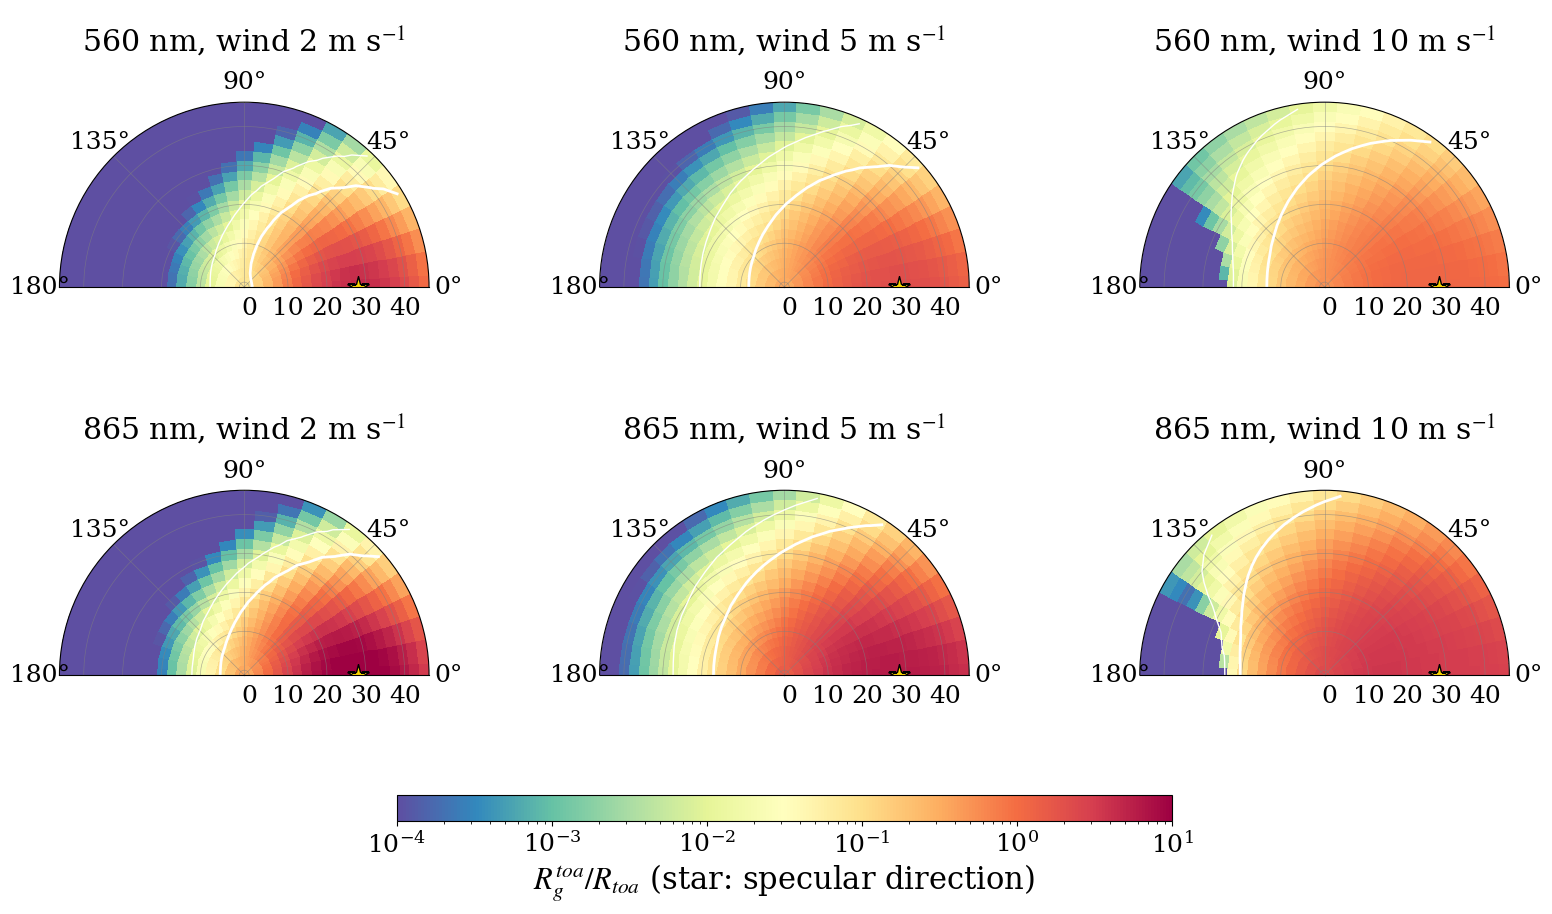

In [9]:
norm = mpl.colors.LogNorm(vmin=1e-4, vmax=10)
fig, axs = plt.subplots(2, 3, figsize=(20, 12), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(hspace=0.05, wspace=0.15)
for irow, wl in enumerate([560, 865]):
    for ax, ws in zip(axs[irow], winds):
        ratio = (Rg_toa.isel(time=it).sel(wind=ws) / Rtoa.isel(time=it)).sel(wl=wl, method='nearest')
        im = polar_map(ax, ratio, norm)
        ax.contour(np.radians(ratio.azi), ratio.vza, ratio.transpose('vza', 'azi'), levels=[0.01, 0.1],
                   colors='w', linewidths=[1, 2])
        ax.plot(0, float(input_db.sza[it]), '*', color='gold', ms=16, mec='k')
        ax.set_title(f'{wl} nm, wind {ws} m s$^{{-1}}$', pad=-30)
cb = fig.colorbar(im, ax=axs, shrink=0.5, aspect=30, location='bottom', pad=0.03)
cb.set_label(r'$R_g^{toa} / R_{toa}$ (star: specular direction)')
plt.show()

Proportion of the viewing geometries of the grid where the sunglint exceeds 1 % and 10 % of the TOA
reflectance:

In [10]:
import pandas as pd

table = {}
for wl in [443, 560, 665, 865]:
    ratio = (Rg_toa.isel(time=it) / Rtoa.isel(time=it)).sel(wl=wl, method='nearest')
    for threshold in [0.01, 0.1]:
        table[(f'{wl} nm', f'> {threshold:.0%}')] = (100 * (ratio > threshold).mean(['vza', 'azi'])).to_series()
pd.DataFrame(table).round(1).rename_axis('wind (m/s)')

443 nm       560 nm       665 nm       865 nm      
             > 1% > 10%   > 1% > 10%   > 1% > 10%   > 1% > 10%
wind (m/s)                                                    
2            46.3  18.7   56.2  30.3   59.6  42.7   63.4  49.9
5            64.6  29.1   75.4  54.7   80.0  62.3   84.4  70.3
10           77.1  45.5   85.5  67.8   88.4  74.5   90.9  82.1

The sunglint contribution grows with the wavelength, where the water-leaving and atmospheric signals
decrease, and with the wind speed, which spreads the glint over a wider range of viewing directions.
For the comparison with satellite observations, the sunglint reflectance at the TOA computed here can be
added to the simulation, or the geometries where it exceeds a given proportion of the signal (for
instance 1 % in the near infrared) can be excluded. The wind speed and direction at the time of the
overpass then determine the actual extent of the glint.